In [1]:
import pandas as pd

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [13]:
!ls /content/drive/Shareddrives/BAX_catalyst/data/

1D_data.csv	3D_data1A2.csv	3D_data1A.csv	3D_data_med_yield_A1.csv  sample_catalyst.csv
3D_data1A1.csv	3D_data1A3.csv	3D_data1B3.csv	3D_data_med_yield_B1.csv


In [3]:
import pandas as pd

# Path to your data folder in Google Drive
folder_path = '/content/drive/Shareddrives/BAX_catalyst/data_sathya_edits/'

# Example of reading a CSV file from that folder
data = pd.read_csv(folder_path + 'data_june_2024.csv')


In [125]:
data

,SampleReference,ReactionTime,Temperature,Pressure,Median,TotalYield
0,MP2_91_1_rerun long 1h,1,200,26,18,2.5
1,MP2_84_1_rerun long 4h,4,200,26,18,41.0
2,MP2_95_1_rerun long 6h,6,200,26,16,62.4
3,MP2_86_1_rerun long 8h,8,200,26,16,75.0
4,MP2_93_1_rerun long 10h,10,200,26,12,70.3
5,MP2_92_1_rerun long 15h,15,200,26,10,55.4
6,MP2_98_1_rerun_long 15h,15,200,26,10,55.0
7,MP2_99_5_rerun long 15h,15,200,26,10,57.0
8,MP2_114_5_15h_hotGC_long,15,200,26,10,58.0
9,MP2_85_1_rerun long 16h,16,200,26,11,54.0


In [165]:
import numpy as np
X = np.array(data[["ReactionTime", "Temperature", "Pressure"]])
y1 = np.array(data[["Median"]])
y2 = np.array(data[["TotalYield"]])/100

In [166]:
# prompt: Train a 1 layer MLP regressor in pytorch. I want to have a sigmoid as the last layer and use mse loss function

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Standardize the features
scaler = StandardScaler()

# Convert to PyTorch tensors
X_train = torch.tensor(X, dtype=torch.float32)
y_train_median = torch.tensor(y1, dtype=torch.float32).reshape(-1, 1)
y_train_yield = torch.tensor(y2, dtype=torch.float32).reshape(-1, 1)

# Define the MLP model
class YieldRegressor(nn.Module):
    def __init__(self, input_size):
        super(YieldRegressor, self).__init__()
        self.fc1 = nn.Linear(input_size, 8)
        self.fc2 = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.fc1(x)
        x = nn.ReLU()(x)
        x = self.fc2(x)
        x = self.sigmoid(x)
        return x

# Define the MLP model
class MedianRegressor(nn.Module):
    def __init__(self, input_size):
        super(MedianRegressor, self).__init__()
        self.fc1 = nn.Linear(input_size, 8)
        self.fc2 = nn.Linear(8, 8)
        self.fc2 = nn.Linear(8, 8)
        self.fc3 = nn.Linear(8, 1)

    def forward(self, x):
        x = self.fc1(x)
        x = nn.ReLU()(x)
        x = self.fc2(x)
        x = nn.ReLU()(x)
        x = self.fc2(x)
        x = nn.ReLU()(x)
        x = self.fc3(x)
        x = nn.ReLU()(x)
        return x

In [168]:
# Instantiate the model
input_size = X_train.shape[1]
yield_regressor = YieldRegressor(input_size)

# Define the loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(yield_regressor.parameters(), lr=0.001)

# Training loop
num_epochs = 500
for epoch in range(num_epochs):
    # Forward pass
    outputs = yield_regressor(X_train)
    loss = criterion(outputs, y_train_yield)

    # Backward and optimize
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [10/500], Loss: 0.3459
Epoch [20/500], Loss: 0.2524
Epoch [30/500], Loss: 0.2114
Epoch [40/500], Loss: 0.1869
Epoch [50/500], Loss: 0.1832
Epoch [60/500], Loss: 0.1817
Epoch [70/500], Loss: 0.1798
Epoch [80/500], Loss: 0.1778
Epoch [90/500], Loss: 0.1758
Epoch [100/500], Loss: 0.1739
Epoch [110/500], Loss: 0.1720
Epoch [120/500], Loss: 0.1703
Epoch [130/500], Loss: 0.1686
Epoch [140/500], Loss: 0.1671
Epoch [150/500], Loss: 0.1656
Epoch [160/500], Loss: 0.1642
Epoch [170/500], Loss: 0.1630
Epoch [180/500], Loss: 0.1618
Epoch [190/500], Loss: 0.1606
Epoch [200/500], Loss: 0.1594
Epoch [210/500], Loss: 0.1583
Epoch [220/500], Loss: 0.1571
Epoch [230/500], Loss: 0.1558
Epoch [240/500], Loss: 0.1543
Epoch [250/500], Loss: 0.1527
Epoch [260/500], Loss: 0.1508
Epoch [270/500], Loss: 0.1486
Epoch [280/500], Loss: 0.1458
Epoch [290/500], Loss: 0.1423
Epoch [300/500], Loss: 0.1379
Epoch [310/500], Loss: 0.1319
Epoch [320/500], Loss: 0.1242
Epoch [330/500], Loss: 0.1145
Epoch [340/500], Lo

In [171]:
# Instantiate the model
input_size = X_train.shape[1]
median_model = MedianRegressor(input_size)

# Define the loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(median_model.parameters(), lr=0.005)

# Training loop
num_epochs = 2000
for epoch in range(num_epochs):
    # Forward pass
    outputs = median_model(X_train)
    loss = criterion(outputs, y_train_median)

    # Backward and optimize
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch+1) % 100 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [100/2000], Loss: 5.8644
Epoch [200/2000], Loss: 5.2998
Epoch [300/2000], Loss: 5.2130
Epoch [400/2000], Loss: 5.1105
Epoch [500/2000], Loss: 4.9881
Epoch [600/2000], Loss: 4.8337
Epoch [700/2000], Loss: 4.6425
Epoch [800/2000], Loss: 4.6545
Epoch [900/2000], Loss: 4.3604
Epoch [1000/2000], Loss: 6.1217
Epoch [1100/2000], Loss: 3.4647
Epoch [1200/2000], Loss: 3.3672
Epoch [1300/2000], Loss: 2.9330
Epoch [1400/2000], Loss: 2.4926
Epoch [1500/2000], Loss: 2.8207
Epoch [1600/2000], Loss: 2.2955
Epoch [1700/2000], Loss: 2.0234
Epoch [1800/2000], Loss: 1.7604
Epoch [1900/2000], Loss: 1.6983
Epoch [2000/2000], Loss: 1.5356


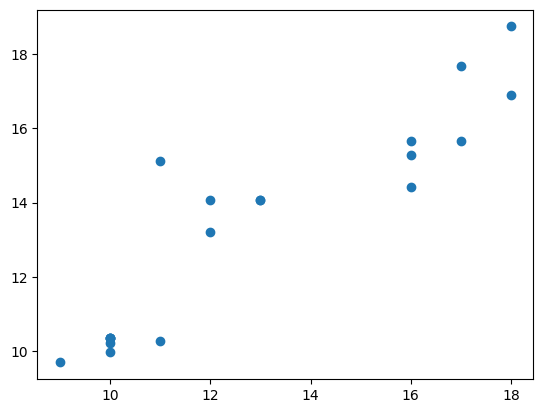

In [174]:
from matplotlib import pyplot as plt
plt.scatter(y_train_median, median_model(X_train).detach().numpy())


In [190]:
import itertools

rxn_times = np.linspace(1, 24, 24)
temps = np.linspace(200, 250, 5)
pressures = np.linspace(18, 50, 9)
X_design_space = np.array(list(itertools.product(rxn_times, temps, pressures)))


In [192]:
# Standardize the features

# Convert to PyTorch tensors
X_design_space = torch.tensor(X_design_space, dtype=torch.float32)

In [193]:
y_design_space_yield = 100 * yield_regressor(X_design_space).detach().numpy()
y_design_space_median = median_model(X_design_space).detach().numpy()

In [194]:
output_df = pd.DataFrame(X_design_space.numpy(), columns=["Time", "Temperature", "Pressure"])
output_df["Median"] = y_design_space_median
output_df["Yield"] = y_design_space_yield

In [195]:
output_df.to_csv("/content/drive/Shareddrives/BAX_catalyst/data_sathya_edits/nn_fitted_interpolation.csv", index=False)

In [189]:
output_df

,Time,Temperature,Pressure,Median,Yield
0,1.0,200.0,18.000000,19.438318,57.047264
1,1.0,200.0,21.555555,19.128246,58.448631
2,1.0,200.0,25.111111,18.818188,59.836418
3,1.0,200.0,28.666666,18.508116,61.208641
4,1.0,200.0,32.222221,18.198044,62.563263
...,...,...,...,...,...
1195,24.0,250.0,35.777779,9.458178,53.177979
1196,24.0,250.0,39.333332,9.861965,54.604984
1197,24.0,250.0,42.888889,10.427536,56.024509
1198,24.0,250.0,46.444443,11.689657,57.434345
